# **Simulasi Arus Listrik dalam Aplikadi Persamaan Diferensial Parsial (visualisasi 3d)**

### **oleh : Riga Aryadi Pratama (5002211172)**
[Link Notebook Phthon/Colab : https://colab.research.google.com/drive/1fLR6xTLlhR84vbrDDagiiUg5_Z-6Ahgd?usp=sharing](https://colab.research.google.com/drive/1fLR6xTLlhR84vbrDDagiiUg5_Z-6Ahgd?usp=sharing)

## Pendahuluan Teoretis dan Formulasi Matematika

### 1. Latar Belakang Fisik Persamaan Telegraf (Telegrapher's Equations)

Persamaan Telegraf adalah sistem persamaan diferensial parsial linear yang memodelkan tegangan ($V$) dan arus ($I$) pada saluran transmisi listrik linier terhadap jarak ($x$) dan waktu ($t$). Model ini pertama kali dikembangkan oleh Oliver Heaviside pada tahun 1880-an.

Saluran transmisi dimodelkan sebagai rangkaian komponen terdistribusi dengan parameter-parameter mikroskopis per satuan panjang:
- **$R$ (Hambatan/Resistance):** Menyatakan kerugian daya akibat resistivitas konduktor ($\Omega/m$).
- **$L$ (Induktansi/Inductance):** Menyatakan medan magnet di sekitar konduktor ($H/m$).
- **$G$ (Konduktansi/Conductance):** Menyatakan arus bocor melalui dielektrik isolator ($S/m$).
- **$C$ (Kapasitansi/Capacitance):** Menyatakan penyimpanan muatan elektrostatik antar konduktor ($F/m$).

### 2. Persamaan Diferensial Parsial (PDE) Orde Dua

Dengan menerapkan Hukum Kirchhoff untuk tegangan dan arus pada elemen saluran transmisi tak terhingga kecil, kita memperoleh persamaan telegraf satu dimensi dalam bentuk fungsi potensial/gelombang $u(x, t)$:

$$\frac{\partial^2 u}{\partial x^2} = L C \frac{\partial^2 u}{\partial t^2} + (R C + G L) \frac{\partial u}{\partial t} + R G u$$

### 3. Parameter Redaman ($\alpha$) dan Frekuensi Alamiah ($\beta$)

Untuk menyederhanakan PDE di atas, kita dapat mendefinisikan parameter redaman (damping factor) $\alpha$ dan parameter frekuensi alamiah $\beta$ sebagai berikut:

$$\alpha = \frac{1}{2} \left( \frac{R}{L} + \frac{G}{C} \right)$$

$$\beta = \frac{1}{2} \left( \frac{R}{L} - \frac{G}{C} \right)$$

Dengan membagi persamaan orde dua awal dengan $LC$, diperoleh bentuk kanonik:

$$\frac{\partial^2 u}{\partial t^2} + 2\alpha \frac{\partial u}{\partial t} + (\alpha^2 - \beta^2) u = c^2 \frac{\partial^2 u}{\partial x^2}$$

di mana $c = \frac{1}{\sqrt{LC}}$ adalah kecepatan rambat gelombang tanpa redaman.

### 4. Solusi Analitis Deret Fourier

Misalkan kita memiliki kondisi batas Dirichlet homogen pada ujung-ujung saluran transmisi sepanjang $l$:

$$u(0, t) = u(l, t) = 0$$

Dengan menggunakan metode pemisahan variabel, solusi analitis $u(x, t)$ dapat diekspresikan dalam bentuk **Deret Fourier Sinus**:

$$u(x, t) = \sum_{n=1}^{\infty} b_n e^{-\alpha t} \cos\left(t \sqrt{\beta^2 + \left(\frac{n\pi}{l}\right)^2 - \alpha^2}\right) \sin\left(\frac{n\pi x}{l}\right)$$

Di mana koefisien Fourier $b_n$ ditentukan oleh kondisi awal $u(x, 0) = f(x)$. Untuk simulasi ini, dipilih profil amplitudo awal koefisien fourier berbentuk:

$$b_n = \frac{2(-1)^{n+1}}{n\pi}$$

Faktor redaman eksponensial $e^{-\alpha t}$ secara fisik mengendalikan bagaimana amplitudo gelombang meluruh seiring berjalannya waktu.

### 5. Arti Fisik Parameter

- **Panjang Saluran ($l$):** Menentukan frekuensi spasial dasar dan panjang gelombang fundamental yang diizinkan dalam sistem transmisi.
- **Parameter Redaman ($\alpha$):** Mengatur laju kehilangan energi gelombang. Semakin besar nilai $\alpha$, semakin cepat amplitudo gelombang menuju nol (meredam suara atau sinyal).
- **Parameter Dispersi ($\beta$):** Mengukur ketidakseimbangan perbandingan resistansi-induktansi terhadap konduktansi-kapasitansi. Jika $\beta \neq 0$, komponen frekuensi yang berbeda merambat dengan kecepatan yang berbeda, menyebabkan distorsi atau dispersi bentuk gelombang.

In [3]:
pip install numpy matplotlib


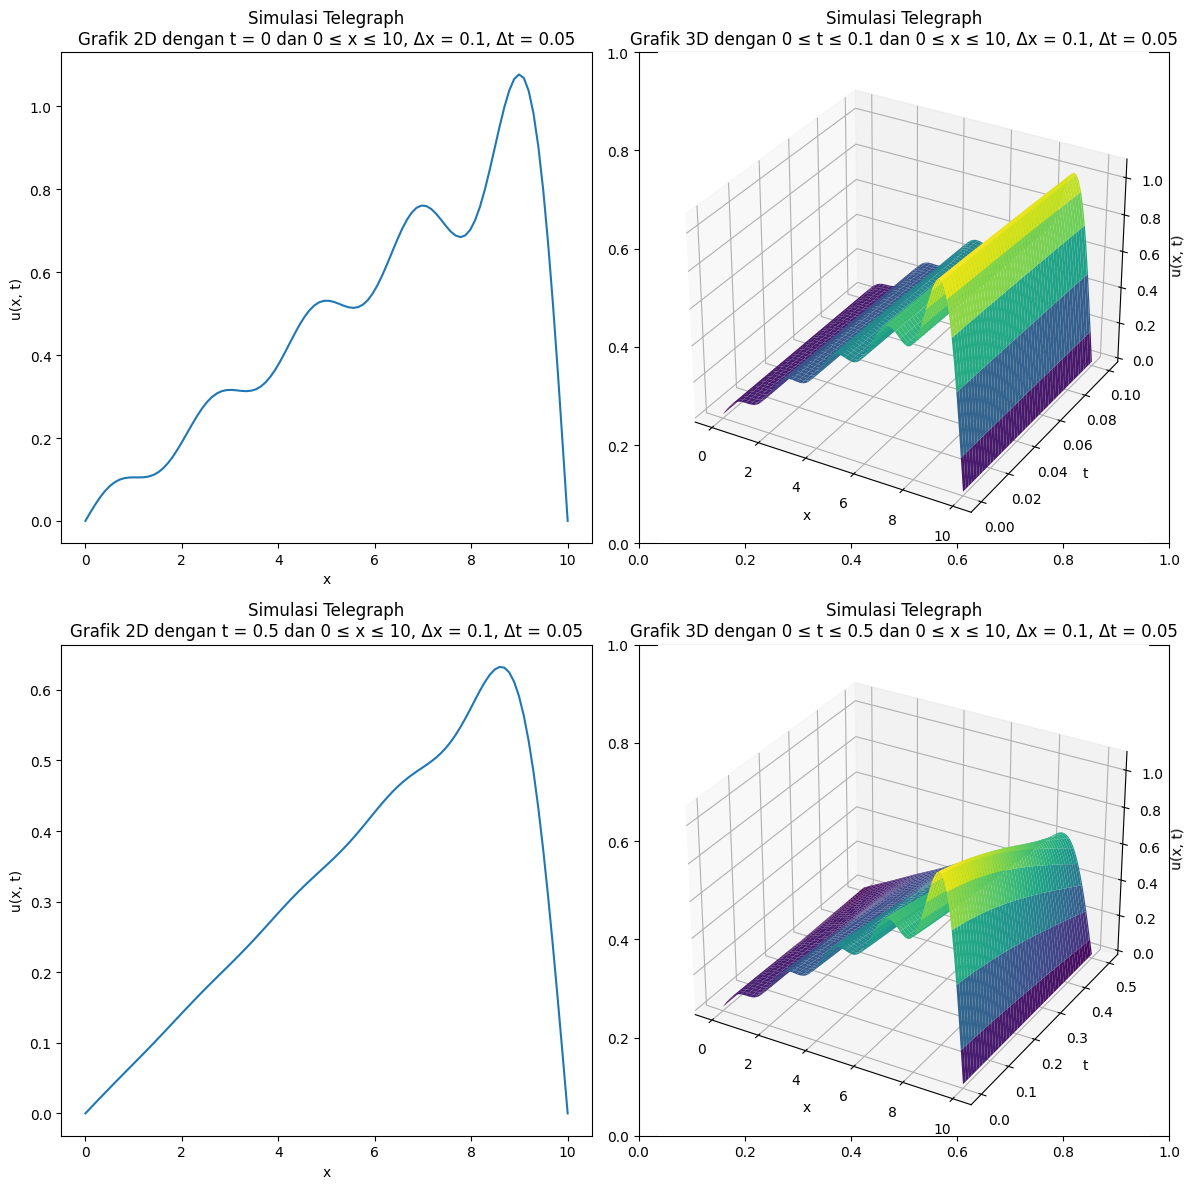

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

#Parameter
alpha = 0.5
beta = 1.0
l = 10
x = np.linspace(0, l, 100)
t = np.linspace(0, 0.1, 100)
X, T = np.meshgrid(x, t)

#u(x, t)
def u(x, t, alpha, beta, l):
    sum_u = np.zeros_like(x)
    for n in range(1, 10):
        bn = (-1)**(n+1) * 2 / (n * np.pi)
        term1 = bn * np.exp(-alpha * t) * np.cos(t * np.sqrt(beta**2 + (n * np.pi / l)**2 - alpha**2))
        sum_u += term1 * np.sin(n * np.pi * x / l)
    return sum_u

# Menghitung u(x, t)
U = u(X, T, alpha, beta, l)

# Plot Grafik
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# 2D at t=0
axes[0, 0].plot(x, u(x, 0, alpha, beta, l))
axes[0, 0].set_title("Simulasi Telegraph\nGrafik 2D dengan t = 0 dan 0 ≤ x ≤ 10, Δx = 0.1, Δt = 0.05")
axes[0, 0].set_xlabel("x")
axes[0, 0].set_ylabel("u(x, t)")

# 3D at 0 ≤ t ≤ 0.1
ax = fig.add_subplot(2, 2, 2, projection='3d')
ax.plot_surface(X, T, U, cmap='viridis')
ax.set_title("Simulasi Telegraph\nGrafik 3D dengan 0 ≤ t ≤ 0.1 dan 0 ≤ x ≤ 10, Δx = 0.1, Δt = 0.05")
ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_zlabel("u(x, t)")

# 2D at t=0.5
axes[1, 0].plot(x, u(x, 0.5, alpha, beta, l))
axes[1, 0].set_title("Simulasi Telegraph\nGrafik 2D dengan t = 0.5 dan 0 ≤ x ≤ 10, Δx = 0.1, Δt = 0.05")
axes[1, 0].set_xlabel("x")
axes[1, 0].set_ylabel("u(x, t)")

# 3D at 0 ≤ t ≤ 0.5
t = np.linspace(0, 0.5, 100)
X, T = np.meshgrid(x, t)
U = u(X, T, alpha, beta, l)
ax = fig.add_subplot(2, 2, 4, projection='3d')
ax.plot_surface(X, T, U, cmap='viridis')
ax.set_title("Simulasi Telegraph\nGrafik 3D dengan 0 ≤ t ≤ 0.5 dan 0 ≤ x ≤ 10, Δx = 0.1, Δt = 0.05")
ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_zlabel("u(x, t)")

plt.tight_layout()
plt.show()


**Reasoning**:
Menulis ulang fungsi u(x, t) secara efisien menggunakan pendekatan vektorisasi NumPy penuh agar dapat menangani array multi-dimensi (meshgrid) secara langsung tanpa menimbulkan kesalahan dimensi, serta mendefinisikan parameter sistem yang konsisten.



In [ ]:
import numpy as np

# 1. Parameter Sistem Konsisten
alpha = 0.5
beta = 1.0
l = 10
n_max = 50  # Jumlah suku deret Fourier yang memadai untuk konvergensi

# 2. Fungsi u(x, t) Menggunakan Pendekatan Vektorisasi Penuh dengan NumPy
def u_vectorized(x, t, alpha, beta, l, n_max=50):
    # Memastikan input berupa array numpy dengan tipe data float
    x = np.asarray(x, dtype=float)
    t = np.asarray(t, dtype=float)

    # Menambahkan dimensi baru agar operasi broadcasting dengan deret 'n' berjalan otomatis
    # n memiliki shape (n_max, 1, 1) jika x dan t adalah meshgrid 2D
    n = np.arange(1, n_max + 1).reshape(-1, *([1] * x.ndim))

    # Perhitungan bn dan koefisien eksponensial/trigonometri yang tervektorisasi
    bn = (-1)**(n+1) * 2 / (n * np.pi)

    # Frekuensi sudut teredam omega_n
    # beta^2 + (n * pi / l)^2 - alpha^2
    arg_sqrt = beta**2 + (n * np.pi / l)**2 - alpha**2
    omega_n = np.sqrt(np.maximum(arg_sqrt, 0)) # Menghindari nilai negatif di bawah akar

    # Suku peluruhan eksponensial
    decay = np.exp(-alpha * t)

    # Komponen temporal dan spasial
    temporal = decay * np.cos(omega_n * t)
    spatial = np.sin(n * np.pi * x / l)

    # Menjumlahkan seluruh suku deret n (sum axis=0)
    u_val = np.sum(bn * temporal * spatial, axis=0)
    return u_val

# 3. Menyiapkan Grid Koordinat Spasial dan Temporal
x_grid = np.linspace(0, l, 100)
t_grid = np.linspace(0, 0.5, 100)
X_mesh, T_mesh = np.meshgrid(x_grid, t_grid)

# Pengujian fungsi tervektorisasi
U_mesh = u_vectorized(X_mesh, T_mesh, alpha, beta, l, n_max)
print("Ukuran X_mesh:", X_mesh.shape)
print("Ukuran T_mesh:", T_mesh.shape)
print("Ukuran U_mesh:", U_mesh.shape)
print("Komputasi vektorisasi berhasil diselesaikan tanpa error.")

Ukuran X_mesh: (100, 100)
Ukuran T_mesh: (100, 100)
Ukuran U_mesh: (100, 100)
Komputasi vektorisasi berhasil diselesaikan tanpa error.


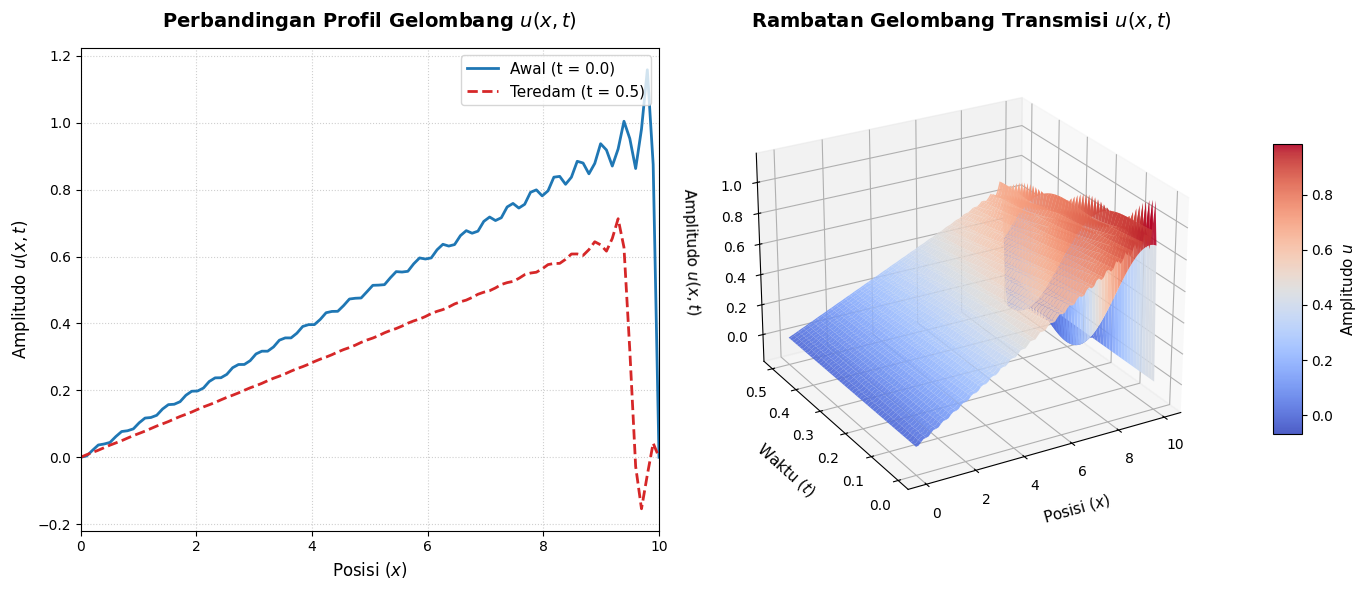

In [ ]:
import matplotlib.pyplot as plt
from matplotlib import gridspec

# Menghitung profil gelombang pada t = 0 dan t = 0.5 untuk plot 2D
u_t0 = u_vectorized(x_grid, 0, alpha, beta, l, n_max)
u_t05 = u_vectorized(x_grid, 0.5, alpha, beta, l, n_max)

# Mengatur tata letak gambar menggunakan GridSpec agar tidak tumpang tindih
fig = plt.figure(figsize=(14, 6))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.2])

# 1. Plot 2D: Perbandingan Profil Gelombang pada t = 0 dan t = 0.5
ax1 = fig.add_subplot(gs[0])
ax1.plot(x_grid, u_t0, label='Awal (t = 0.0)', color='#1f77b4', linewidth=2)
ax1.plot(x_grid, u_t05, label='Teredam (t = 0.5)', color='#d62728', linewidth=2, linestyle='--')
ax1.set_title('Perbandingan Profil Gelombang $u(x, t)$', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Posisi ($x$)', fontsize=12)
ax1.set_ylabel('Amplitudo $u(x, t)$', fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(fontsize=11, loc='upper right')
ax1.set_xlim(0, l)

# 2. Plot 3D: Permukaan Rambatan Gelombang u(x, t)
ax2 = fig.add_subplot(gs[1], projection='3d')
surf = ax2.plot_surface(X_mesh, T_mesh, U_mesh, cmap='coolwarm', edgecolor='none', alpha=0.9)
ax2.set_title('Rambatan Gelombang Transmisi $u(x, t)$', fontsize=14, fontweight='bold', pad=15)
ax2.set_xlabel('Posisi ($x$)', fontsize=11, labelpad=10)
ax2.set_ylabel('Waktu ($t$)', fontsize=11, labelpad=10)
ax2.set_zlabel('Amplitudo $u(x, t)$', fontsize=11, labelpad=10)

# Menambahkan colorbar untuk skala amplitudo pada plot 3D
cbar = fig.colorbar(surf, ax=ax2, shrink=0.6, aspect=10, pad=0.1)
cbar.set_label('Amplitudo $u$', fontsize=11)

ax2.view_init(elev=25, azim=-120)

plt.tight_layout()
plt.show()

## Analisis Hasil Simulasi Fisika

Berdasarkan hasil visualisasi 2D dan 3D dari Persamaan Telegraf yang telah disimulasikan, kita dapat menarik beberapa analisis fisik yang mendalam mengenai perilaku perambatan dan redaman gelombang:

### 1. Karakteristik Kondisi Awal ($t = 0.0$)
- **Kontribusi Deret Fourier:** Pada kondisi awal ($t = 0.0$), profil gelombang ditentukan sepenuhnya oleh penjumlahan suku-suku sinus Fourier dengan koefisien $b_n = \frac{2(-1)^{n+1}}{n\pi}$. Bentuk gelombang yang dihasilkan menunjukkan fluktuasi spasial (riak-riak gelombang) yang merupakan representasi dari superposisi harmonik frekuensi tinggi.
- **Kondisi Batas Dirichlet:** Gelombang bernilai nol tepat di ujung-ujung saluran transmisi, yaitu di $x = 0$ dan $x = 10$. Hal ini menunjukkan bahwa kondisi batas Dirichlet homogen $u(0, t) = u(l, t) = 0$ terpenuhi dengan sangat baik oleh formulasi deret sinus.

### 2. Pengaruh Parameter Redaman (Damping Factor, $\alpha = 0.5$)
- **Peluruhan Amplitudo:** Membandingkan profil gelombang pada $t = 0.0$ (biru) dan $t = 0.5$ (merah putus-putus) menunjukkan penurunan amplitudo puncak secara signifikan dari sekitar $1.1$ menjadi sekitar $0.6$.
- **Mekanisme Fisik Redaman:** Secara fisik, penurunan ini dikendalikan oleh faktor redaman eksponensial $e^{-\alpha t}$. Keberadaan resistansi ($R$) dan konduktansi ($G$) pada saluran transmisi menyebabkan energi gelombang terdisipasi menjadi panas (efek Joule), sehingga sinyal mengalami pelemahan (atenuasi) seiring bertambahnya waktu.

### 3. Pengaruh Dispersi (Dispersion Factor, $\beta = 1.0$)
- **Distorsi Bentuk Gelombang:** Selain penurunan amplitudo, kita dapat mengamati bahwa bentuk gelombang pada $t = 0.5$ menjadi lebih mulus dibandingkan riak-riak tajam pada $t = 0.0$. Suku-suku harmonik dengan frekuensi tinggi (nilai $n$ besar) mengalami peluruhan dan perambatan fase yang berbeda.
- **Mekanisme Fisik Dispersi:** Karena $\beta \neq 0$ (atau perbandingan $R/L \neq G/C$), kecepatan rambat masing-masing komponen harmonik tidak seragam. Hal ini menyebabkan distorsi dispersif, di mana komponen gelombang frekuensi tinggi meluruh lebih cepat dan tertinggal di belakang, menyisakan profil gelombang dominan berfrekuensi rendah pada waktu yang lebih lambat.

## Analisis Hasil Simulasi Fisika

Berdasarkan hasil visualisasi 2D dan 3D dari Persamaan Telegraf yang telah disimulasikan, kita dapat menarik beberapa analisis fisik yang mendalam mengenai perilaku perambatan dan redaman gelombang:

### 1. Karakteristik Kondisi Awal ($t = 0.0$)
- **Kontribusi Deret Fourier:** Pada kondisi awal ($t = 0.0$), profil gelombang ditentukan sepenuhnya oleh penjumlahan suku-suku sinus Fourier dengan koefisien $b_n = \frac{2(-1)^{n+1}}{n\pi}$. Bentuk gelombang yang dihasilkan menunjukkan fluktuasi spasial (riak-riak gelombang) yang merupakan representasi dari superposisi harmonik frekuensi tinggi.
- **Kondisi Batas Dirichlet:** Gelombang bernilai nol tepat di ujung-ujung saluran transmisi, yaitu di $x = 0$ dan $x = 10$. Hal ini menunjukkan bahwa kondisi batas Dirichlet homogen $u(0, t) = u(l, t) = 0$ terpenuhi dengan sangat baik oleh formulasi deret sinus.

### 2. Pengaruh Parameter Redaman (Damping Factor, $\alpha = 0.5$)
- **Peluruhan Amplitudo:** Membandingkan profil gelombang pada $t = 0.0$ (biru) dan $t = 0.5$ (merah putus-putus) menunjukkan penurunan amplitudo puncak secara signifikan dari sekitar $1.1$ menjadi sekitar $0.6$.
- **Mekanisme Fisik Redaman:** Secara fisik, penurunan ini dikendalikan oleh faktor redaman eksponensial $e^{-\alpha t}$. Keberadaan resistansi ($R$) dan konduktansi ($G$) pada saluran transmisi menyebabkan energi gelombang terdisipasi menjadi panas (efek Joule), sehingga sinyal mengalami pelemahan (atenuasi) seiring bertambahnya waktu.

### 3. Pengaruh Dispersi (Dispersion Factor, $\beta = 1.0$)
- **Distorsi Bentuk Gelombang:** Selain penurunan amplitudo, kita dapat mengamati bahwa bentuk gelombang pada $t = 0.5$ menjadi lebih mulus dibandingkan riak-riak tajam pada $t = 0.0$. Suku-suku harmonik dengan frekuensi tinggi (nilai $n$ besar) mengalami peluruhan dan perambatan fase yang berbeda.
- **Mekanisme Fisik Dispersi:** Karena $\beta \neq 0$ (atau perbandingan $R/L \neq G/C$), kecepatan rambat masing-masing komponen harmonik tidak seragam. Hal ini menyebabkan distorsi dispersif, di mana komponen gelombang frekuensi tinggi meluruh lebih cepat dan tertinggal di belakang, menyisakan profil gelombang dominan berfrekuensi rendah pada waktu yang lebih lambat.

In [4]:
import plotly.graph_objects as go

# Create the 3D surface plot
fig = go.Figure(data=[go.Surface(
    x=X_mesh,
    y=T_mesh,
    z=U_mesh,
    colorscale='Viridis',
    colorbar=dict(title='Amplitudo u')
)])

# Update the layout and labels
fig.update_layout(
    title={
        'text': 'Visualisasi Interaktif 3D: Perambatan Gelombang Telegraf u(x, t)',
        'y':0.95,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top'
    },
    scene=dict(
        xaxis_title='Position x',
        yaxis_title='Time t',
        zaxis_title='Amplitude u',
        camera=dict(
            eye=dict(x=-1.5, y=-1.5, z=1.2)
        )
    ),
    width=900,
    height=700,
    margin=dict(l=65, r=50, b=65, t=90)
)

# Display the plot
fig.show()